# Results: Undiagnosed Chronic Condition Suspecting

**Question:** which adults in a primary-care panel probably have diabetes or chronic kidney disease that nobody has diagnosed, and is a model better than the screening guidelines clinics already follow?

- **Data:** NHANES (CDC). Every participant gets lab tests and is asked whether they were ever told they have the condition, so "undiagnosed" can be observed directly.
- **Design:** train on 2017–March 2020, test on August 2021–August 2023 (temporal external validation). All rates are survey-weighted to the US adult population.
- **This notebook reads the saved outputs in `reports/`.** To regenerate them from raw data, run `python run_all.py`.

In [1]:
import json, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_colwidth", 80)
R = json.load(open("reports/results.json"))
res = {r["task"]: r for r in R["results"]}
pct = lambda x: f"{100*x:.1f}%"
print("Synthetic run?", R["synthetic"])

Synthetic run? False


## 1. Is the data right?
Our numbers should line up with published CDC figures: about 1 in 5 adults with diabetes are undiagnosed (CDC also counts fasting glucose; we use HbA1c only, so ours is a bit lower), and about 9 in 10 adults with CKD don't know they have it.

In [2]:
a = pd.read_csv("reports/data_audit.csv")
chk = a[a.variable.str.startswith("CHECK")].pivot(index="variable", columns="cycle", values="weighted_value")
chk.index = chk.index.str.replace("CHECK ", "")
chk.map(pct)

cycle,2017-2020,2021-2023
variable,,
ckd_lab (eGFR<60 or UACR>=30),13.1%,12.4%
ckd_unaware_share,86.8%,87.3%
diabetes_total (dx or HbA1c>=6.5),14.0%,13.9%
diabetes_undiagnosed_share_of_total,16.4%,15.4%


## 2. Headline: the model vs. the guidelines

In [3]:
rows = []
for t, r in res.items():
    m = r["test"][r["chosen_model"]]
    rows.append({"task": t, "test n (cases)": f"{r['n_test']:,} ({r['cases_test']})",
                 "prevalence": pct(r["prevalence_test_weighted"]), "model": r["chosen_model"],
                 "AUROC (95% CI)": f"{m['auroc']:.3f} ({r['ci95']['auroc'][0]:.3f}-{r['ci95']['auroc'][1]:.3f})",
                 **{f"guideline AUROC: {b}": f"{r['test'][b]['auroc']:.3f}" for b in r["matched"] if not b.startswith("Random")}})
pd.DataFrame(rows).set_index("task").fillna("")

,test n (cases),prevalence,model,AUROC (95% CI),guideline AUROC: ADA risk test (>=5),guideline AUROC: USPSTF age 35-70 & BMI>=25,guideline AUROC: Guideline risk factor (any of DM/HTN/CVD/age>=60)
task,,,,,,,
dm_visit,"4,911 (152)",2.5%,logistic,0.816 (0.772-0.856),0.767,0.733,
dm_bmp,"4,665 (146)",2.6%,logistic,0.940 (0.916-0.962),0.765,0.729,
ckd_visit,"5,118 (791)",12.6%,logistic,0.783 (0.756-0.807),,,0.751
alb_bmp,"4,778 (451)",8.1%,logistic,0.751 (0.712-0.789),,,0.707


**Same testing volume as each guideline:** if a clinic tests exactly as many patients as the guideline would, but picks them with the model, how many more undiagnosed cases does it find?

In [4]:
rows = []
for t, r in res.items():
    for b, m in r["matched"].items():
        lo, hi = r["ci95"][f"dsens|{b}"]
        rows.append({"task": t, "guideline": b, "share tested": pct(m["baseline"]["share_flagged"]),
                     "cases found: guideline": pct(m["baseline"]["sensitivity"]),
                     "cases found: model": pct(m["model"]["sensitivity"]),
                     "difference (95% CI)": f"{100*lo:+.1f} to {100*hi:+.1f} pts"})
pd.DataFrame(rows)

,task,guideline,share tested,cases found: guideline,cases found: model,difference (95% CI)
0,dm_visit,ADA risk test (>=5),27.1%,62.8%,70.7%,-2.4 to +20.0 pts
1,dm_visit,USPSTF age 35-70 & BMI>=25,43.5%,67.9%,86.2%,+5.9 to +31.2 pts
2,dm_bmp,ADA risk test (>=5),27.1%,62.6%,95.1%,+22.7 to +43.0 pts
3,dm_bmp,USPSTF age 35-70 & BMI>=25,43.9%,67.9%,97.6%,+20.9 to +39.4 pts
4,dm_bmp,Random glucose >=140 mg/dL,1.4%,41.9%,33.5%,-12.5 to -0.7 pts
5,ckd_visit,Guideline risk factor (any of DM/HTN/CVD/age>=60),47.3%,80.2%,82.7%,+0.1 to +5.3 pts
6,alb_bmp,Guideline risk factor (any of DM/HTN/CVD/age>=60),45.1%,74.1%,76.7%,-1.3 to +6.8 pts


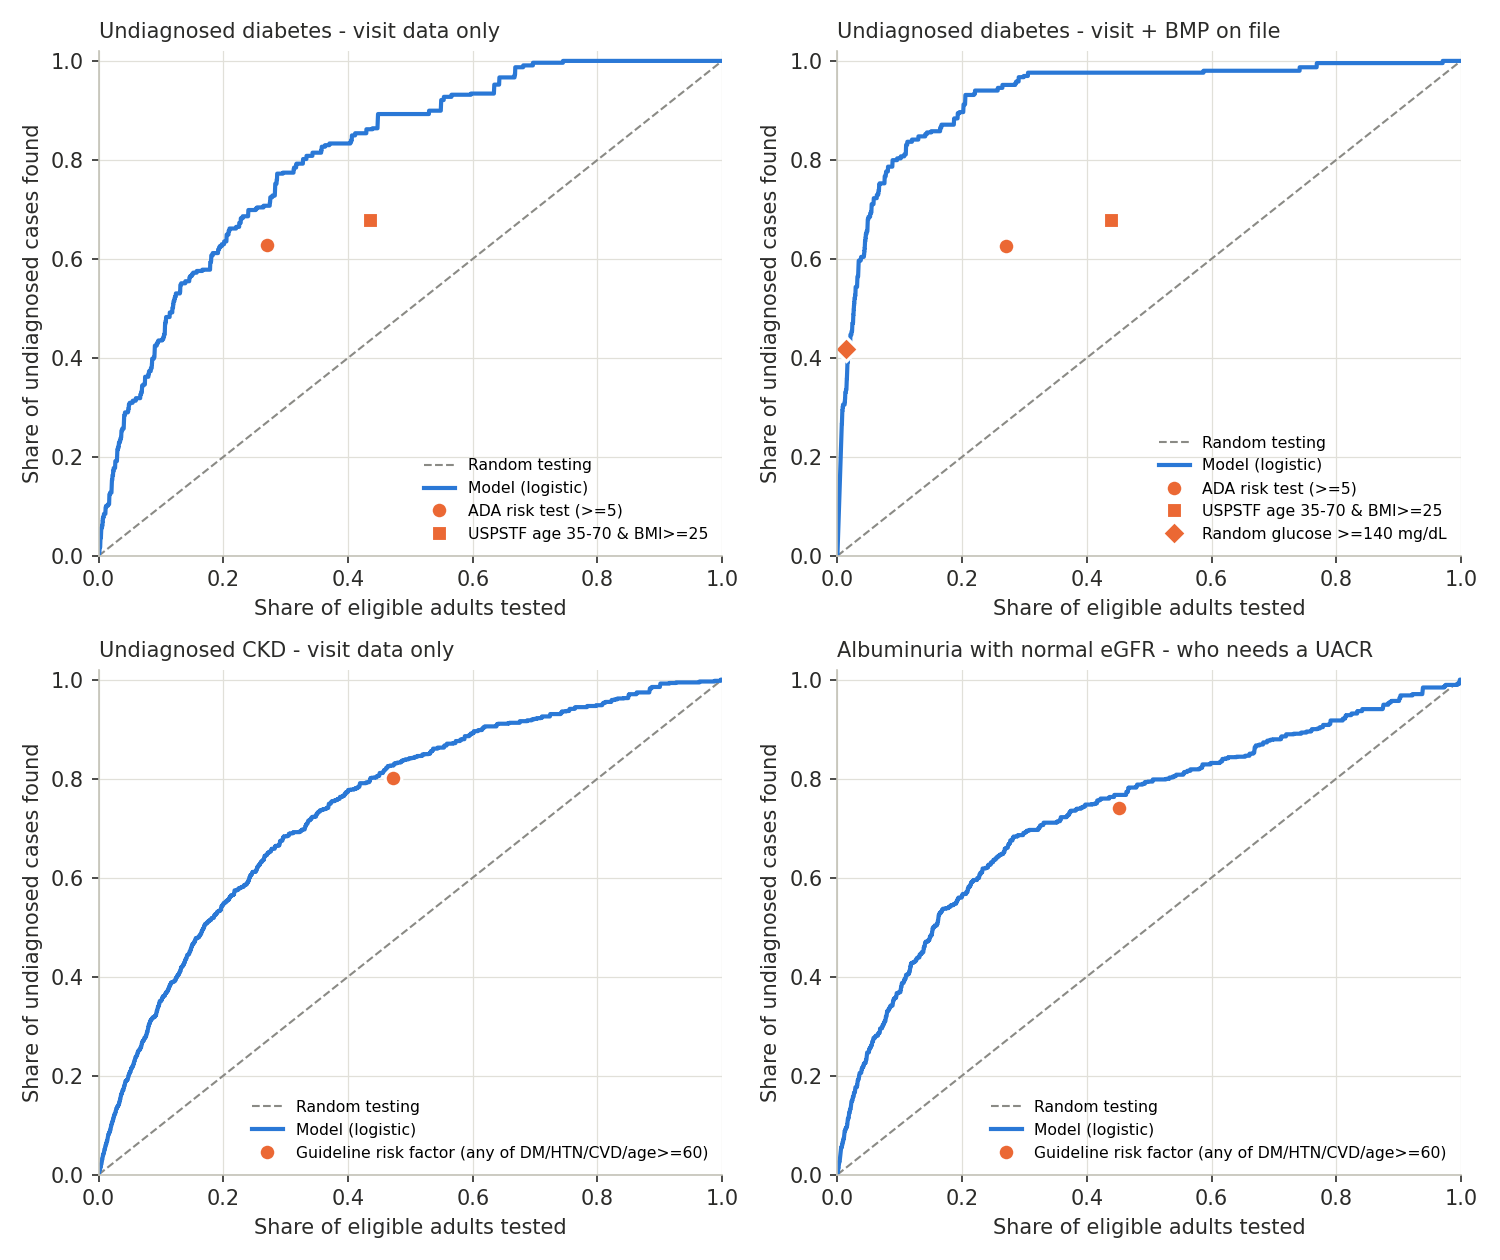

In [5]:
display(Image("reports/figures/gain_charts.png", width=900))

**Reading the charts:** the blue curve shows the share of undiagnosed cases found as you test more of the population, in model order. Each orange marker is a guideline at its own testing volume. A marker below the curve means the model finds more cases for the same amount of testing.

- **Diabetes:** the model clearly beats USPSTF. With routine labs on file (`dm_bmp`), it finds about 95% of cases at the ADA test's volume, versus 63% for the ADA test.
- **CKD:** the guideline rule is already fairly good when it tests nearly half of everyone. The model's real advantage is at **smaller budgets**: by flagging just 20% of adults, it finds 55% of undiagnosed CKD.

## 3. Error analysis: three things the first run got wrong

### 3a. Ignoring the survey design made predictions about 1.6× too high
NHANES deliberately oversamples older, Black, Hispanic, Asian and low-income adults. A model fit without the survey weights learns the *sample's* diabetes rate (4.2%), not the population's (2.7%).

In [6]:
pd.DataFrame([{"task": t, "observed/expected, unweighted fit": f"{r['test']['logistic_unweighted (diagnostic)']['obs_exp_ratio']:.2f}",
               "observed/expected, survey-weighted fit": f"{r['test'][r['chosen_model']]['obs_exp_ratio']:.2f}"}
              for t, r in res.items()]).set_index("task")

,"observed/expected, unweighted fit","observed/expected, survey-weighted fit"
task,,
dm_visit,0.64,0.85
dm_bmp,0.64,0.78
ckd_visit,0.92,1.02
alb_bmp,0.85,0.91


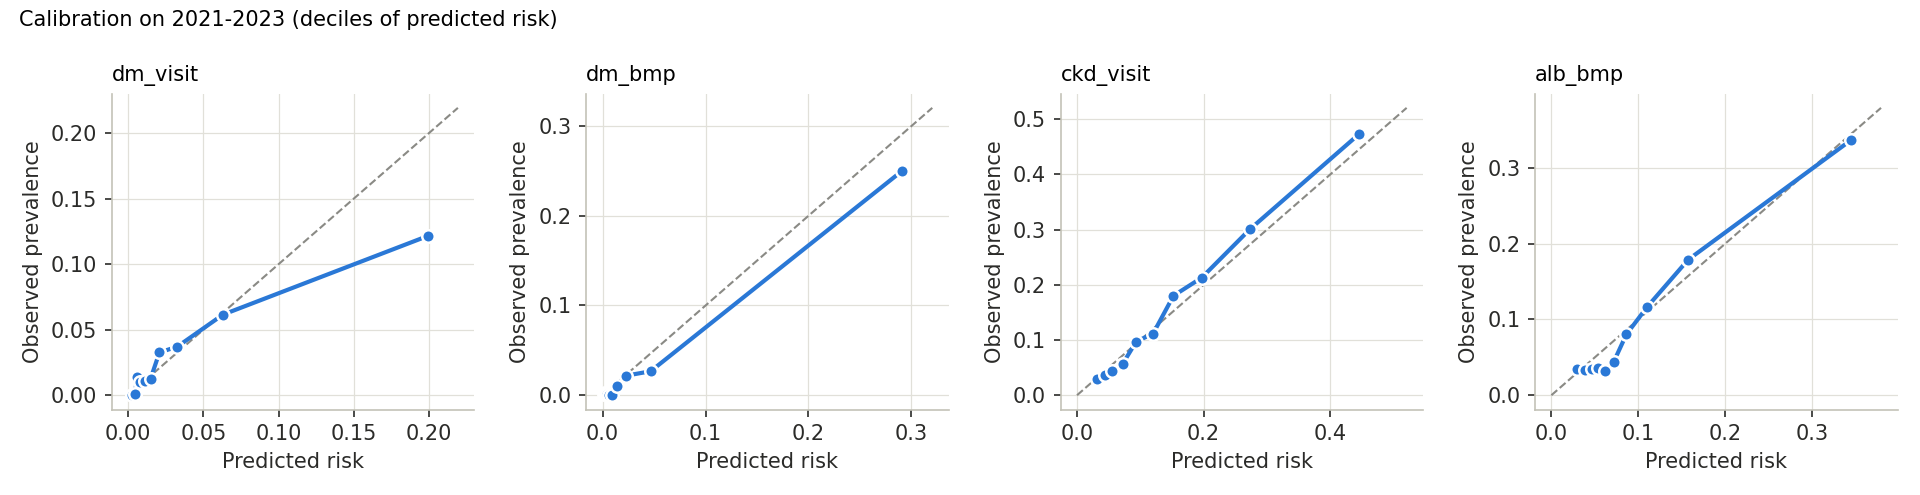

In [7]:
display(Image("reports/figures/calibration.png", width=900))

Weighting fixed most of the gap (1.00 = perfect). The diabetes models still over-predict somewhat in 2021–2023, partly because measured prevalence fell between cycles. In deployment, a model like this would get an **intercept recalibration** on local data before go-live.

### 3b. The top "reason" for a diabetes flag was a missing answer
In v1, the strongest diabetes signal after age was *"prediabetes question unanswered."* People told they are "borderline" skip that question, so the signal was real but couldn't be shown to a doctor. v2 adds an explicit **told-borderline** feature and never displays missing-data indicators as reasons:

In [8]:
pd.read_csv("reports/suspect_examples_dm_visit.csv")[["age", "female", "p", "y", "reasons"]].head(6)

,age,female,p,y,reasons
0,72.0,0.0,0.624330,0.0,dx_borderline; age=72; bp_meds
1,72.0,0.0,0.620922,0.0,dx_borderline; waist=160; age=72
2,61.0,1.0,0.591924,1.0,dx_borderline; waist=122; dbp=98
3,48.0,1.0,0.574151,0.0,dx_borderline; waist=149; bmi=63
4,64.0,1.0,0.570041,0.0,dx_borderline; waist=126; bmi=52
5,37.0,1.0,0.547528,0.0,dx_borderline; waist=150; bmi=51


### 3c. A one-line lab rule beat the model at very small volumes
At the ~1.4% of patients with random glucose ≥ 140 mg/dL, the simple rule finds more cases than the model's top 1.4%. Putting the rule first and letting the model rank everyone else (a hybrid) makes almost no difference from 5% capacity upward: the model already uses glucose. **In practice:** keep a hard alert for very high glucose, and use the model for outreach prioritization.

In [9]:
r = res["dm_bmp"]
pd.DataFrame([{"flag top": b, "model": pct(r["budgets"][b]["sensitivity"]), "hybrid": pct(r["hybrid_budgets"][b]["sensitivity"])}
              for b in r["budgets"]]).set_index("flag top")

,model,hybrid
flag top,,
5%,68.5%,69.5%
10%,80.3%,80.3%
20%,89.7%,89.7%
30%,97.0%,97.0%


## 4. Who gets missed? Subgroup audit
Race/ethnicity and income are **not** model inputs, and eGFR uses the race-free CKD-EPI 2021 equation. These variables are used only to check whether performance holds across groups. The panels show sensitivity when flagging the top 20%.

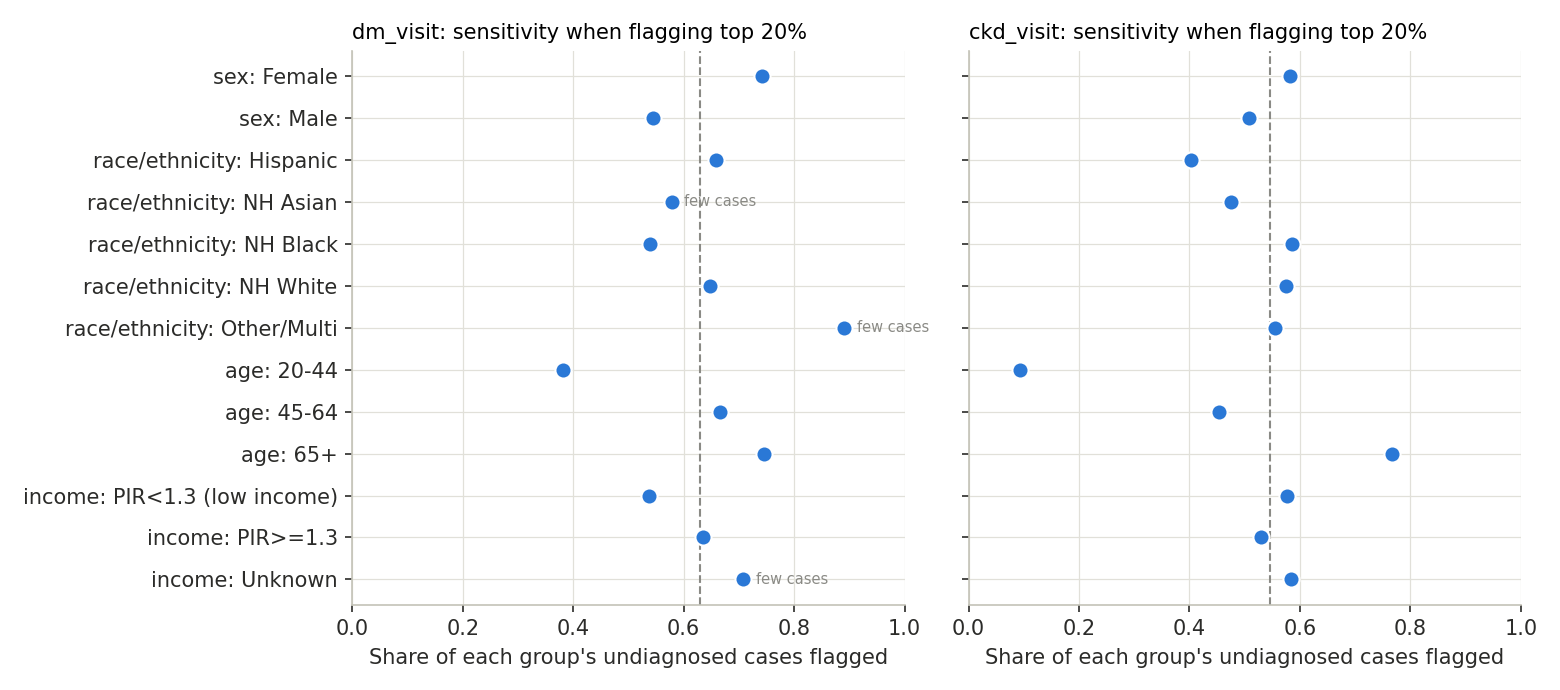

In [10]:
display(Image("reports/figures/subgroups.png", width=900))

In [11]:
s = pd.DataFrame(res["ckd_visit"]["subgroups"])
s[["group", "level", "n", "cases", "prevalence", "sensitivity", "obs_exp_ratio", "small_sample"]].round(3)

,group,level,n,cases,prevalence,sensitivity,obs_exp_ratio,small_sample
0,sex,Female,2796,408,0.130,0.582,0.924,False
1,sex,Male,2322,383,0.121,0.507,1.162,False
2,race_ethnicity,Hispanic,875,106,0.093,0.402,0.868,False
3,race_ethnicity,NH Asian,285,41,0.131,0.476,1.261,False
4,race_ethnicity,NH Black,587,134,0.185,0.585,1.272,False
5,race_ethnicity,NH White,3063,457,0.123,0.574,0.975,False
6,race_ethnicity,Other/Multi,308,53,0.143,0.554,1.190,False
7,age,20-44,1704,87,0.050,0.094,0.984,False
8,age,45-64,1781,225,0.117,0.454,0.865,False
9,age,65+,1633,479,0.298,0.766,1.174,False


**Findings to act on:**
- **CKD in Hispanic adults:** sensitivity is noticeably lower (about 40% vs. 57% for White adults at the same threshold). Part of this is lower prevalence, but it is worth a group-specific threshold review.
- **CKD in Black and Asian adults:** risk is under-predicted (observed/expected ≈ 1.26–1.27). Removing race from the model is the right call for fairness, but these groups then need a calibration check.
- **Diabetes by sex:** sensitivity is lower for men (54% vs. 74% for women).
- **Age:** younger adults (20–44) are rarely flagged under a population-wide budget. That is expected given their low prevalence, but it means a separate, younger-adult pathway would be needed to catch early disease.

## 5. Forecasting impact for a 10,000-adult panel
Scenario: the care team can send outreach testing to **20% of the panel** this year. The **guideline strategy** tests eligible patients, chosen at random when more are eligible than capacity allows. The **model strategy** tests the top-ranked patients. The Monte Carlo combines model uncertainty (bootstrap) with operational assumptions: test completion 40–80%, confirmation and documentation 70–95%, lab cost, and $ per RAF point.

In [12]:
rows = []
for f in R["forecasts"]:
    s = f["summary"]; q = lambda k, pre="": f"{pre}{s[k]['p50']:,.0f} [{pre}{s[k]['p10']:,.0f}-{pre}{s[k]['p90']:,.0f}]"
    rows.append({"task": f["task"], "population": f["population"], "extra confirmed dx": q("incremental_dx"),
                 "lab $/dx model": f"${s['lab_cost_per_dx_model']['p50']:,.0f}",
                 "lab $/dx guideline": f"${s['lab_cost_per_dx_guideline']['p50']:,.0f}",
                 "annual RAF value (65+)": q("incremental_raf_value_usd", "$") if f["population"] == "65+" else "-"})
pd.DataFrame(rows)

,task,population,extra confirmed dx,lab $/dx model,lab $/dx guideline,annual RAF value (65+)
0,dm_visit,all,21 [12-31],$199,$271,-
1,dm_visit,65+,54 [32-78],$142,$275,"$106,410 [$62,686-$155,770]"
2,dm_bmp,all,56 [42-73],$136,$268,-
3,dm_bmp,65+,117 [85-155],$90,$263,"$231,547 [$167,610-$313,883]"
4,ckd_visit,all,129 [102-159],$46,$74,-
5,ckd_visit,65+,222 [170-288],$30,$53,"$161,311 [$104,850-$225,580]"
6,alb_bmp,all,95 [75-118],$69,$118,-
7,alb_bmp,65+,156 [112-210],$50,$101,$0 [$0-$0]


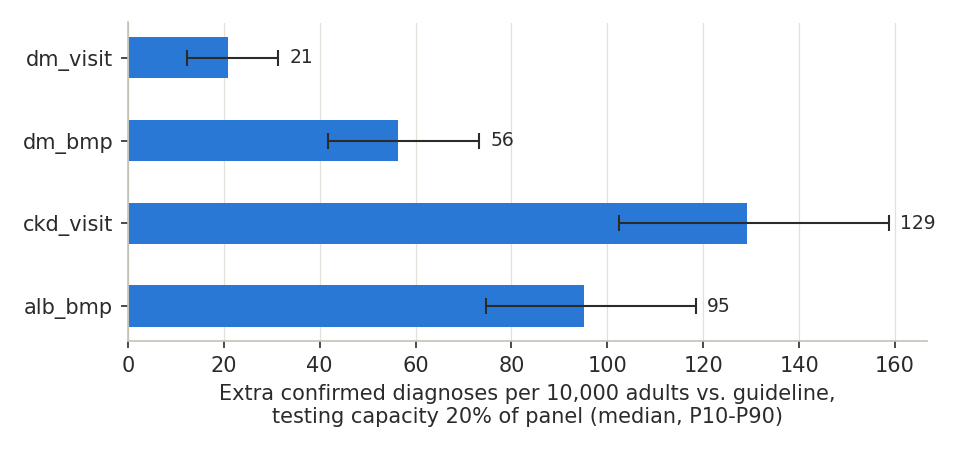

In [13]:
display(Image("reports/figures/impact.png", width=700))

**How to read the dollar figures.** They are the annual CMS-HCC V28 value of *documenting conditions that are real and lab-confirmed*: diabetes HCC 38 = 0.166, CKD stage 3 HCC 329 = 0.127. Albuminuria-only CKD (stages 1–2) has no payment HCC, so the `alb_bmp` value is \$0 even though it finds about 95 extra cases per 10,000 adults. That makes it a pure care-quality win. The main uncertainty is operational: test completion moves the result about 2× between its low and high values:

In [14]:
pd.DataFrame([{"task": f["task"], "assumption": t["assumption"], "range": f"{t['low']}-{t['high']}",
               "extra dx (low-high)": f"{t['incremental_dx_low']:.0f}-{t['incremental_dx_high']:.0f}"}
              for f in R["forecasts"] if f["population"] == "65+" for t in f["tornado"]])

,task,assumption,range,extra dx (low-high)
0,dm_visit,complete,0.4-0.8,37-75
1,dm_visit,confirm,0.7-0.95,46-62
2,dm_visit,usd_raf,10000-14000,56-56
3,dm_bmp,complete,0.4-0.8,81-161
4,dm_bmp,confirm,0.7-0.95,100-135
5,dm_bmp,usd_raf,10000-14000,121-121
6,ckd_visit,complete,0.4-0.8,153-307
7,ckd_visit,confirm,0.7-0.95,190-257
8,ckd_visit,usd_raf,10000-14000,230-230
9,alb_bmp,complete,0.4-0.8,106-211


## 6. Takeaways
1. **Risk-based prioritization beats blanket guidelines, most clearly for diabetes.** The advantage grows when routine lab results are already on file (AUROC 0.94).
2. **For CKD, the model's value is efficiency, not coverage.** It matches the guideline's case-finding while testing far fewer people, and it is the only option when capacity is limited.
3. **Survey-weighted training is necessary.** Ignoring it miscalibrated risk by about 1.6×, most for the least-oversampled group.
4. **Simple rules still have a place.** A hard glucose threshold should stay as a deterministic alert next to the model.
5. **Before deployment:** recalibrate on local EHR data, review CKD thresholds and calibration for Hispanic, Black and Asian patients, and confirm single-visit lab definitions with repeat testing.

*Limitations (single-visit lab definitions, self-reported diagnosis, NHANES vs. EHR data) are listed in the README.*